# Multimodal Movie Recap: YouTube Film → Summary Story → Peak Points → Recap Under 10 Minutes

**AI11 · Module 8 · Multimodal AI Systems: Speech, Text, and Conversational Agents · Assignment 1**

**Problem statement.** A full-length film takes more than an hour to watch. The task is to build a
multimodal AI system that takes a YouTube movie, processes its video, audio and text, writes a summary
story, finds the important (peak) moments with their timestamps, cuts those moments out of the film and
joins them into a recap that runs for less than ten minutes. The summary is evaluated with BLEU.

**Objectives**
1. Implement a multimodal pipeline that processes video, audio and text.
2. Apply speech-to-text and summarisation to produce a concise summary story.
3. Identify peak points and map them to time indices in the original film.
4. Extract the relevant segments (OpenCV) and combine them into a recap of less than ten minutes.

**Workflow**

`YouTube Video → Movie → Audio + Video → Transcript → Summary Story → Peak Points → Time Index → Video Segment Extraction → Movie Recap → BLEU Evaluation`

**Input film.** *Detour* (1945, dir. Edgar G. Ulmer), a public-domain film noir of 67 minutes with heavy
first-person voice-over narration. Public-domain status allows the recap clips to be shared freely, and a
human-written Wikipedia plot summary serves as the BLEU reference.

**How this notebook relates to the code.** The full pipeline lives in the `recap/` package and is run with
`python run_pipeline.py`. Slow stages (22 min of transcription, 31 min of LLM summarisation on a CPU)
cache their outputs as JSON. This notebook loads those cached outputs, re-runs the light components live
to show that each one works on its own, and interprets every result.

## 1. Environment and reproducibility

**Purpose.** Fix random seeds, record library versions and load the shared configuration so that every
later section reads the same paths and parameters.

**Methodology.** The project root is added to the import path, `config.yaml` is loaded through the same
helper the pipeline uses, and the versions of the key libraries are printed.

**Inference.** The table below confirms the software stack used for the reported results.

**Insights.** Every model in the pipeline is pre-trained and used zero-shot; there is no training step,
so reproducibility depends on fixed model versions, temperature 0 for the LLM and fixed seeds for the
random baseline.

**Summary.** With the environment fixed, the next section inspects the input film.

In [1]:
# Imports, seeds and configuration shared by every section
import json, random, sys, time, warnings
from pathlib import Path

import cv2
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from recap.utils import load_config, load_json, fmt_ts

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

cfg = load_config(ROOT / "config.yaml")
OUT = Path(cfg["output_dir"])
VIDEO = cfg["input"]["local_path"]
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"

import faster_whisper, sentence_transformers, transformers, nltk, sacrebleu
versions = {"python": sys.version.split()[0], "opencv": cv2.__version__, "librosa": librosa.__version__,
            "faster-whisper": faster_whisper.__version__, "transformers": transformers.__version__,
            "sentence-transformers": sentence_transformers.__version__, "nltk": nltk.__version__,
            "sacrebleu": sacrebleu.__version__, "numpy": np.__version__}
pd.DataFrame([versions]).T.rename(columns={0: "version"})

,version
python,3.14.0
opencv,5.0.0
librosa,1.0.0
faster-whisper,1.2.1
transformers,5.2.0
sentence-transformers,5.4.0
nltk,3.10.3
sacrebleu,2.6.0
numpy,2.4.2


## 2. Input: YouTube video → movie file

**Purpose.** Confirm that the downloaded film is complete and readable before any processing.

**Methodology.** `recap/ingest.py` downloads the film with yt-dlp, explicitly selecting the **original
English audio track** (this upload also carries auto-dubbed Russian, Korean and Portuguese tracks). OpenCV
then reads the stream properties, and six frames are sampled evenly across the running time.

**Inference.** See the stream properties and the frame strip below.

**Insights.** Choosing the audio track is a real multimodal pitfall: picking the default track
blindly could have fed a machine-dubbed voice to speech recognition.

**Summary.** The film is valid, so the soundtrack can be separated from the picture.

,fps,frame_count,width,height,duration_seconds
0,29.97,121627,640,480,4058.29


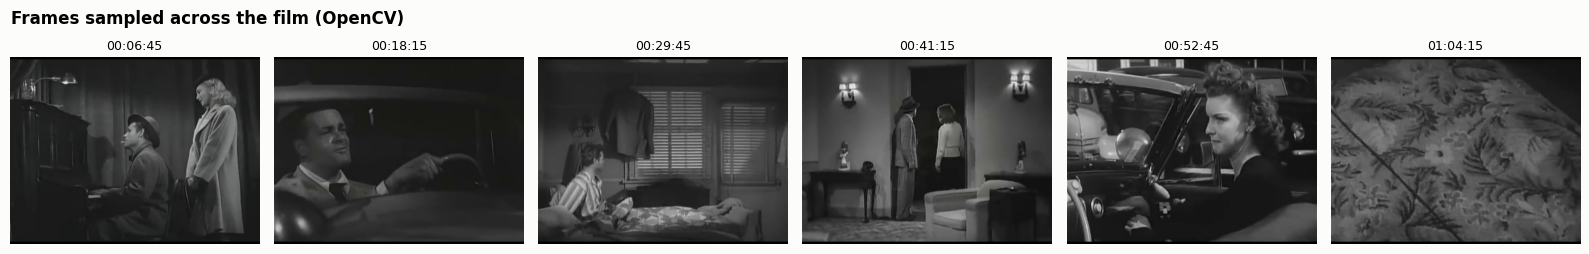

In [2]:
# Probe the film with OpenCV and sample six evenly spaced frames
from recap.ingest import probe_video

info = probe_video(VIDEO)
display(pd.DataFrame([{k: (round(v, 2) if isinstance(v, float) else v) for k, v in info.items() if k != "path"}]))

cap = cv2.VideoCapture(VIDEO)
times = np.linspace(0.1, 0.95, 6) * info["duration_seconds"]
fig, axes = plt.subplots(1, 6, figsize=(16, 2.6))
for ax, t in zip(axes, times):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(t * info["fps"]))
    ok, frame = cap.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(fmt_ts(t), fontsize=9)
    ax.axis("off")
cap.release()
fig.suptitle("Frames sampled across the film (OpenCV)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Observation.** The film is 640×480 at 30 fps and runs for 67 min 38 s; the frames are black and white.

**Interpretation.** Black-and-white footage carries no colour information, so the hue and saturation
channels used for shot detection are nearly flat; brightness (the value channel) does most of the work.

**Key insight.** The visual features must rely on brightness and motion rather than colour for this film.

## 3. Audio extraction (movie → audio + video)

**Purpose.** Separate the soundtrack from the picture so speech recognition and audio analysis can run on it.

**Methodology.** ffmpeg (bundled with `imageio-ffmpeg`, so no system install is required) demuxes the
soundtrack to a 16 kHz mono WAV, the format Whisper expects, plus an MP3 copy. The plot shows the waveform
of the whole film and a log-mel spectrogram of a 20-second dialogue excerpt.

**Inference.** See the charts.

**Insights.** A 16 kHz mono signal is enough for speech: it keeps the band up to 8 kHz in which most speech
energy lies, while cutting the data size by a factor of about six compared with 48 kHz stereo.

**Summary.** The clean speech track is ready for transcription.

Soundtrack: 67.6 min at 16000 Hz, peak amplitude 0.89


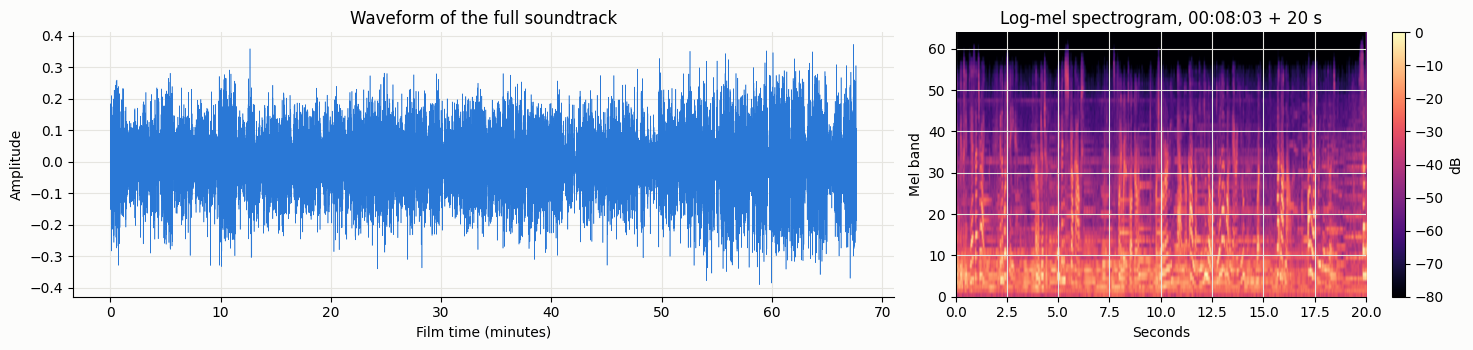

In [3]:
# Load the extracted soundtrack; plot the full waveform and a log-mel spectrogram of one excerpt
wav_path = OUT / "audio" / "audio_16k_mono.wav"
y, sr = librosa.load(wav_path, sr=16000)
print(f"Soundtrack: {len(y) / sr / 60:.1f} min at {sr} Hz, peak amplitude {np.abs(y).max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
step = 400  # downsample for plotting only
axes[0].plot(np.arange(0, len(y), step) / sr / 60, y[::step], color=BLUE, lw=0.4)
axes[0].set(title="Waveform of the full soundtrack", xlabel="Film time (minutes)", ylabel="Amplitude")

start = 8 * 60 + 3  # a dialogue scene at 08:03
excerpt = y[start * sr:(start + 20) * sr]
mel = librosa.power_to_db(librosa.feature.melspectrogram(y=excerpt, sr=sr, n_mels=64), ref=np.max)
img = axes[1].imshow(mel, origin="lower", aspect="auto", cmap="magma", extent=[0, 20, 0, 64])
axes[1].set(title=f"Log-mel spectrogram, {fmt_ts(start)} + 20 s", xlabel="Seconds", ylabel="Mel band")
fig.colorbar(img, ax=axes[1], label="dB")
plt.tight_layout()
plt.show()

**Observation.** The waveform peaks below 0.5 of full scale; the spectrogram shows the stacked
harmonic bands of voices, separated by short pauses.

**Interpretation.** The 1945 soundtrack is quiet and band-limited. This mattered later: clean text-to-speech
narration was far louder than the film dialogue and initially masked it in the recap, so the renderer now
matches narration loudness to the film's speech level.

**Key insight.** Audio levels have to be balanced across sources, otherwise the original dialogue in the
recap becomes hard to hear and speech recognition misses it.

## 4. Speech-to-text: transcript with a time index

**Purpose.** Convert the soundtrack to text while keeping when every line was spoken; these timestamps
are the time index used throughout the rest of the pipeline.

**Methodology.** `faster-whisper` runs OpenAI's Whisper `small.en` model (244 M parameters) through
CTranslate2 with int8 weights on the CPU, with voice-activity filtering and word-level timestamps.
`condition_on_previous_text=False` prevents the repetition loops Whisper can fall into on long audio.

**Inference.** See the statistics and the sample lines below.

**Insights.** Decoding confidence (the exponent of the average log-probability) is high for most lines;
low-confidence lines are usually music, overlapping speech or very short exclamations.

**Summary.** The timestamped transcript is the text modality for summarisation and peak detection.

,segments,words,speech minutes,share of film with speech,ASR runtime (min),median confidence
0,946,8418,39.3,58%,21.8,0.843


,start,end,text
0,00:06:15,00:06:19,"But how we felt about each other, well, there was nothing very unusual in that."
1,00:06:19,00:06:22,"I was an ordinary healthy guy and she was an ordinary healthy girl,"
2,00:06:22,00:06:25,"When you add those two together, you get an ordinary, healthy romance,"
3,00:06:26,00:06:27,which is the old story.
4,00:06:28,00:06:28,Sure.
5,00:06:29,00:06:32,"But somehow, the most wonderful thing in the world."
6,00:06:33,00:06:42,"Well, I was a pretty lucky guy."
7,00:06:55,00:06:57,"Mr. Padarovsky, I presume."


Word-level timestamps for one line: [('Sure.', 388.44)]


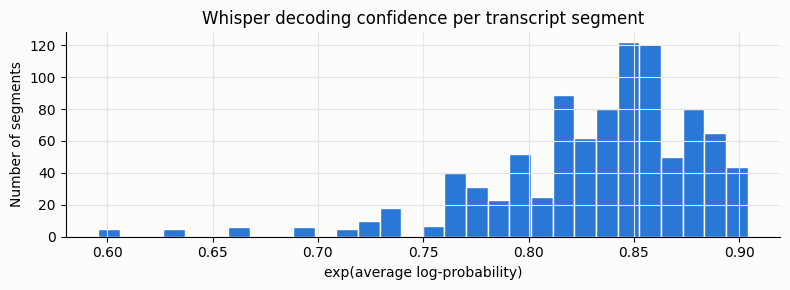

In [4]:
# Transcript statistics, sample lines and decoding confidence
tr = load_json(OUT / "transcript.json")
segs = tr["segments"]
words = sum(len(s["text"].split()) for s in segs)
conf = np.exp([s["avg_logprob"] for s in segs])
speech_time = sum(s["end"] - s["start"] for s in segs)
display(pd.DataFrame([{"segments": len(segs), "words": words, "speech minutes": round(speech_time / 60, 1),
                       "share of film with speech": f"{speech_time / tr['info']['audio_duration']:.0%}",
                       "ASR runtime (min)": round(tr["info"]["processing_seconds"] / 60, 1),
                       "median confidence": round(float(np.median(conf)), 3)}]))
display(pd.DataFrame([{"start": fmt_ts(s["start"]), "end": fmt_ts(s["end"]), "text": s["text"]} for s in segs[60:68]]))
print("Word-level timestamps for one line:", [(w["word"].strip(), w["start"]) for w in segs[64]["words"]])

plt.figure(figsize=(8, 3))
plt.hist(conf, bins=30, color=BLUE, edgecolor="white")
plt.title("Whisper decoding confidence per transcript segment")
plt.xlabel("exp(average log-probability)")
plt.ylabel("Number of segments")
plt.tight_layout()
plt.show()

**Observation.** The transcript has 946 segments covering a little under half of the film's running time;
the confidence histogram is concentrated at the high end with a thin tail of uncertain lines.

**Interpretation.** Speech fills under half of the film, which is normal for a feature film: music, silent
action and pauses fill the rest. Word timestamps give sub-second precision for the time index.

**Key insight.** Transcription took about 22 minutes for 67 minutes of audio on a CPU (about 3× faster than
real time); it is the second most expensive stage and is therefore cached.

## 5. Multimodal signals: audio, video and text emotion

**Purpose.** Measure how intense each moment of the film is in each modality, so peak points are not
chosen from text alone.

**Methodology.**
* **Audio (librosa):** RMS loudness, onset strength (spectral flux) and the fluctuation of amplitude within
  each second. The last follows the session's heuristic that a calm speaker has a steady peak amplitude while
  an agitated one does not. They are combined into an *arousal* score per second.
* **Video (OpenCV):** one pass over the film at 2 frames per second. Shot cuts are detected when the
  Bhattacharyya distance between consecutive HSV histograms exceeds 0.35; motion is the mean absolute
  grey-level difference between samples. They are combined into a *visual activity* score per second.
* **Text (transformers):** a DistilRoBERTa emotion classifier labels each transcript segment; the intensity
  is 1 − P(neutral).

**Inference.** See the emotion distribution and the shot statistics below.

**Insights.** Each modality is computed independently and fused later (post-fusion), which keeps each one
testable on its own and lets the fusion weights be tuned without recomputing features.

**Summary.** These per-second and per-segment curves feed the peak-point stage.

Shot cuts detected: 312  |  median shot length: 8.0 s
Audio arousal: mean 0.51, 95th percentile 0.71
Visual activity: mean 0.34, 95th percentile 0.55


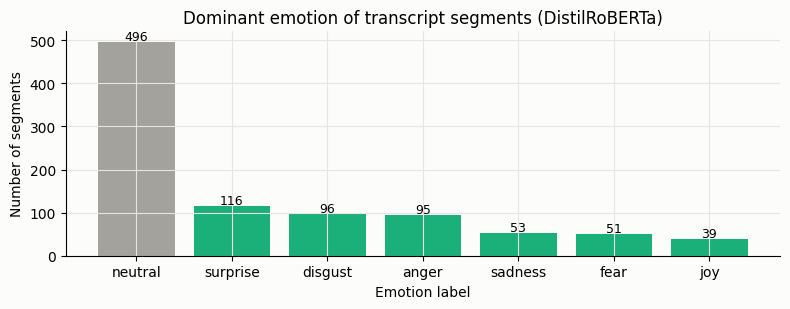

In [5]:
# Load cached feature curves and summarise each modality
fa, fv, fe = (load_json(OUT / f) for f in ("features_audio.json", "features_visual.json", "features_text_emotion.json"))
shots = np.array(fv["shot_boundaries"])
print(f"Shot cuts detected: {len(shots)}  |  median shot length: {np.median(np.diff(shots)):.1f} s")
print(f"Audio arousal: mean {np.mean(fa['arousal']):.2f}, 95th percentile {np.percentile(fa['arousal'], 95):.2f}")
print(f"Visual activity: mean {np.mean(fv['activity']):.2f}, 95th percentile {np.percentile(fv['activity'], 95):.2f}")

labels = pd.Series([e["label"] for e in fe]).value_counts()
plt.figure(figsize=(8, 3.2))
plt.bar(labels.index, labels.values, color=[GREY if l == "neutral" else AQUA for l in labels.index])
for i, v in enumerate(labels.values):
    plt.text(i, v + 5, str(v), ha="center", fontsize=9)
plt.title("Dominant emotion of transcript segments (DistilRoBERTa)")
plt.xlabel("Emotion label")
plt.ylabel("Number of segments")
plt.tight_layout()
plt.show()

**Observation.** About half of the segments are neutral; surprise, disgust and anger are the most common
non-neutral emotions, while joy is rare. 312 shot cuts were detected.

**Interpretation.** The emotional profile fits a film noir: tense, suspicious and hostile exchanges
dominate. Non-neutral lines are therefore a useful signal of dramatic moments.

**Key insight.** Text emotion is the strongest of the three non-semantic signals for this film. The ablation
in Section 9 shows the fusion raises the average emotion intensity of the chosen peaks from 0.56 to 0.78.

## 6. Text processing and summarisation: the summary story

**Purpose.** Turn about 9,000 words of transcript into a short story that a viewer can follow.

**Methodology.** The transcript is split into 13 chunks of about 5 minutes each. A local LLM
(**Qwen2.5-7B-Instruct** served by Ollama, temperature 0) summarises each chunk in one or two sentences,
receiving the story written so far as context (rolling context). Each sentence keeps the time span of its
chunk. Three safeguards came from experiments: a cast list from the opening credits (the transcript has no
speaker labels), an instruction to name a character only when the name is spoken, and a filter that drops
near-duplicate sentences. A TextRank extractive summary of the same length is computed as a baseline.

**Inference.** The table lists each chunk with the story sentence(s) it produced.

**Insights.** Earlier attempts with a 3B model and a single "rewrite everything" step produced 46 sentences
and invented events; the experiment log (`outputs/experiments/SUMMARY_EXPERIMENTS.md`) records each run.

**Summary.** Each story sentence now has a coarse time span; the next stage pins it to an exact moment.

In [6]:
# Story sentences with the transcript chunk (time span) each one was written from
summ = load_json(OUT / "summary.json")
story_df = pd.DataFrame([{"#": i + 1, "chunk time span": f"{fmt_ts(summ['chunks'][c]['start'])}-{fmt_ts(summ['chunks'][c]['end'])}",
                          "story sentence": s} for i, (s, c) in enumerate(zip(summ["story_sentences"], summ["sentence_chunks"]))])
print(f"Backend: {summ['backend']}  |  {len(summ['story_sentences'])} sentences, {len(summ['story'].split())} words "
      f"(compression {words / len(summ['story'].split()):.0f}:1 versus the transcript)")
story_df

Backend: ollama:qwen2.5:7b  |  13 sentences, 315 words (compression 27:1 versus the transcript)


,#,chunk time span,story sentence
0,1,00:02:03-00:07:02,"Al plays a song that reminds him of his girlfriend, Sue, causing him distress and leading him to argue with the club..."
1,2,00:07:03-00:11:54,"Al's girlfriend Sue decides to leave for Hollywood, causing a heated argument about their future plans and leaving A..."
2,3,00:12:18-00:17:17,"Al calls Sue, learns she's working as a hashlinger in Hollywood, and decides to hitchhike to Los Angeles, reflecting..."
3,4,00:17:18-00:22:03,"Al picks up Vera, a hitchhiker, and debates whether to keep her or drop her off, deciding to continue driving her to..."
4,5,00:22:10-00:27:02,"Al realizes he must hide Charles Haskell's body and take his car to avoid being implicated, deciding to drive away d..."
5,6,00:27:11-00:31:57,"Al drives to the California state line, where he hides Charles Haskell's body and takes his car, then checks into a ..."
6,7,00:31:57-00:36:50,"Al picks up Vera, who turns out to be Charles Haskell's accomplice, complicating his plan to avoid suspicion."
7,8,00:36:50-00:41:50,"Al and Vera decide to sell Charles Haskell's car to avoid suspicion, with Vera insisting on accompanying Al to ensur..."
8,9,00:41:54-00:46:53,"Al and Vera discuss their situation, with Vera urging Al to sell the car and leave quickly, while Al struggles with ..."
9,10,00:46:58-00:51:46,"Al and Vera argue over selling Charles Haskell's car, with Vera insisting on keeping the money and Al reluctantly ag..."


## 7. Peak points and time-index mapping

**Purpose.** For every story sentence, find the single moment in the film that best shows it.

**Methodology.**
1. **Alignment.** The transcript is cut into 30-second windows (10-second hop). Story sentences and windows
   are embedded with `all-MiniLM-L6-v2`. A **monotonic dynamic-programming alignment** chooses one window per
   sentence so that the total similarity is maximal *and* the windows appear in story order. Each sentence may
   only align inside its own chunk's time span.
2. **Peak picking.** Within ±45 s of the aligned window, every transcript segment receives a post-fusion score:
   `0.40·semantic + 0.15·centrality + 0.15·text emotion + 0.15·audio arousal + 0.15·visual activity`.
   The best segment is the peak point; its Whisper start time is the **time index**.

The first cell runs the alignment component on a toy matrix to show that order is enforced; the second shows
the similarity matrix of the real film with the chosen path.

**Inference.** See the outputs below.

**Insights.** Without the order constraint, a sentence about the ending can match an early scene that
happens to use the same words (names such as "Haskell" recur throughout the film).

**Summary.** The chosen peaks and their timestamps are listed in the table at the end of this section.

In [7]:
# Component test: the DP alignment keeps story order even when a later column scores higher
from recap.peaks import monotonic_alignment

toy = np.array([[0.1, 0.1, 0.2, 0.1, 0.1, 0.1, 0.9, 0.1],
                [0.1, 0.1, 0.1, 0.1, 0.8, 0.1, 0.1, 0.5]])
print("Greedy best window per sentence:", toy.argmax(axis=1).tolist(), "(out of order)")
print("Monotonic DP alignment:        ", monotonic_alignment(toy, min_gap=1), "(order preserved)")

Greedy best window per sentence: [6, 4] (out of order)
Monotonic DP alignment:         [6, 7] (order preserved)


14:55:22 | INFO | Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/103 [00:00<00:00, 10082.46it/s, Materializing param=embeddings.LayerNorm.bias]

Loading weights:   1%|          | 1/103 [00:00<00:00, 137.90it/s, Materializing param=embeddings.LayerNorm.bias]  

Loading weights:   2%|▏         | 2/103 [00:00<00:00, 142.87it/s, Materializing param=embeddings.LayerNorm.weight]

...

Loading weights:  99%|█████████▉| 102/103 [00:00<00:00, 191.64it/s, Materializing param=pooler.dense.bias]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 191.64it/s, Materializing param=pooler.dense.weight]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 191.64it/s, Materializing param=pooler.dense.weight]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 183.67it/s, Materializing param=pooler.dense.weight]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


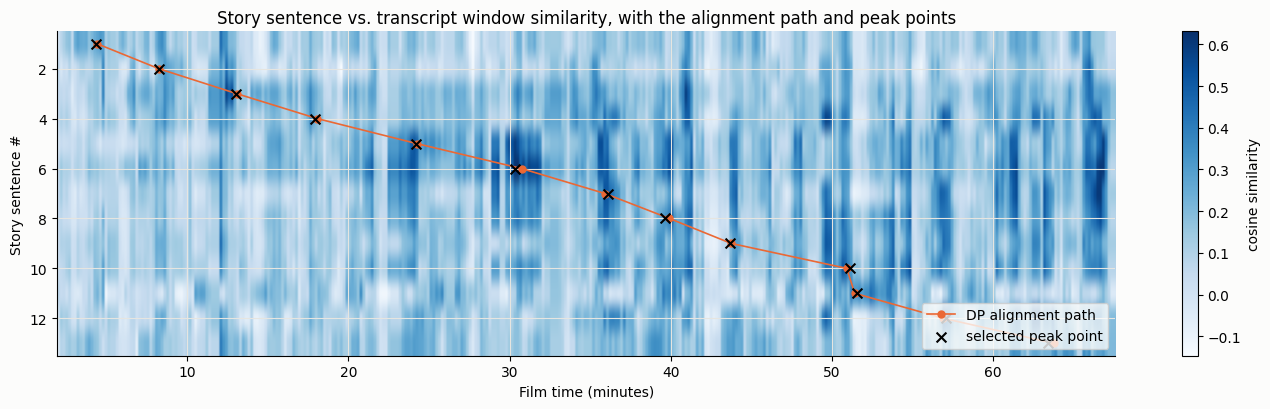

,#,time index,peak line (transcript),emotion,semantic,centrality,text_emotion,audio,visual,fused
0,1,00:04:19,"Sue, she was always selling it too.",disgust,0.8272,0.6086,0.7951,0.4232,0.4101,0.6664
1,2,00:08:13,"Al, look, I love you. You know I do.",joy,0.8202,0.6755,0.9286,0.5142,0.5112,0.7225
2,3,00:13:00,"Oh, baby, it's great to hear from you, too.",joy,0.5480,0.6688,0.9831,0.6789,0.3636,0.6234
3,4,00:17:54,I tossed her out of the car in her ear. Was I wrong. Give,anger,0.5742,0.8747,0.9278,0.3117,0.3552,0.6001
4,5,00:24:13,fell out of the car why if Haskell came to which of course he couldn't even he,surprise,1.0000,0.6770,0.7549,0.5075,0.2750,0.7322
5,6,00:30:21,Not have to be Charles Haskell until I got to some city where I could leave the,neutral,0.9486,0.9296,0.6714,0.5335,0.3324,0.7495
6,7,00:36:07,Vera must be the woman Haskell had mentioned.,neutral,1.0000,0.4937,0.1386,0.5177,0.2559,0.6109
7,8,00:39:38,They wonder where the owner is.,surprise,0.6462,0.5118,0.9877,0.5195,0.6074,0.6524
8,9,00:43:41,"Sure, Sherry, died of old age.",sadness,0.6368,0.6904,0.9794,0.4607,0.6873,0.6774
9,10,00:51:05,"You're my wife, Vera Haskell.",neutral,0.9841,0.6972,0.2679,0.6598,0.3006,0.6825


In [8]:
# Real film: story-sentence x transcript-window similarity, with the DP path and the final peaks
from recap.peaks import build_windows
from recap.summarize import embed

pk = load_json(OUT / "peaks.json")
windows = build_windows(segs, cfg["peaks"]["window_seconds"], cfg["peaks"]["window_hop_seconds"])
model = cfg["peaks"]["embedding_model"]
sim = embed(summ["story_sentences"], model) @ embed([w["text"] for w in windows], model).T
centres = np.array([(w["start"] + w["end"]) / 2 for w in windows]) / 60

plt.figure(figsize=(14, 4.2))
plt.imshow(sim, aspect="auto", cmap="Blues", extent=[centres[0], centres[-1], len(sim) + 0.5, 0.5])
plt.colorbar(label="cosine similarity")
path_t = [centres[j] for j in pk["alignment_path"]]
plt.plot(path_t, np.arange(1, len(sim) + 1), "o-", color=ORANGE, ms=5, lw=1.2, label="DP alignment path")
plt.scatter([p["timestamp"] / 60 for p in pk["peaks"]], np.arange(1, len(sim) + 1), marker="x", color="black",
            s=50, label="selected peak point", zorder=3)
plt.title("Story sentence vs. transcript window similarity, with the alignment path and peak points")
plt.xlabel("Film time (minutes)")
plt.ylabel("Story sentence #")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

peak_df = pd.DataFrame([{"#": p["index"], "time index": p["timestamp_hms"], "peak line (transcript)": p["transcript"][:80],
                         "emotion": p["emotion_label"], **{k: v for k, v in p["scores"].items()}} for p in pk["peaks"]])
peak_df

**Observation.** The orange path climbs steadily from the top-left to the bottom-right, and each
selected peak (×) sits close to the path. Fused scores range from about 0.60 to 0.78.

**Interpretation.** The alignment follows the film chronologically, as a plot summary should. The bright
cells off the path show where a purely greedy match would have jumped to the wrong part of the film.

**Key insight.** Two levels of time index are produced: a coarse one (the chunk a sentence came from) and a
fine one (the Whisper timestamp of the peak line), both stored in `peaks.csv`.

### Multimodal timeline of the whole film

The figure below stacks the three modality curves, the fused salience curve with the numbered peak points,
and the clips that were finally extracted.

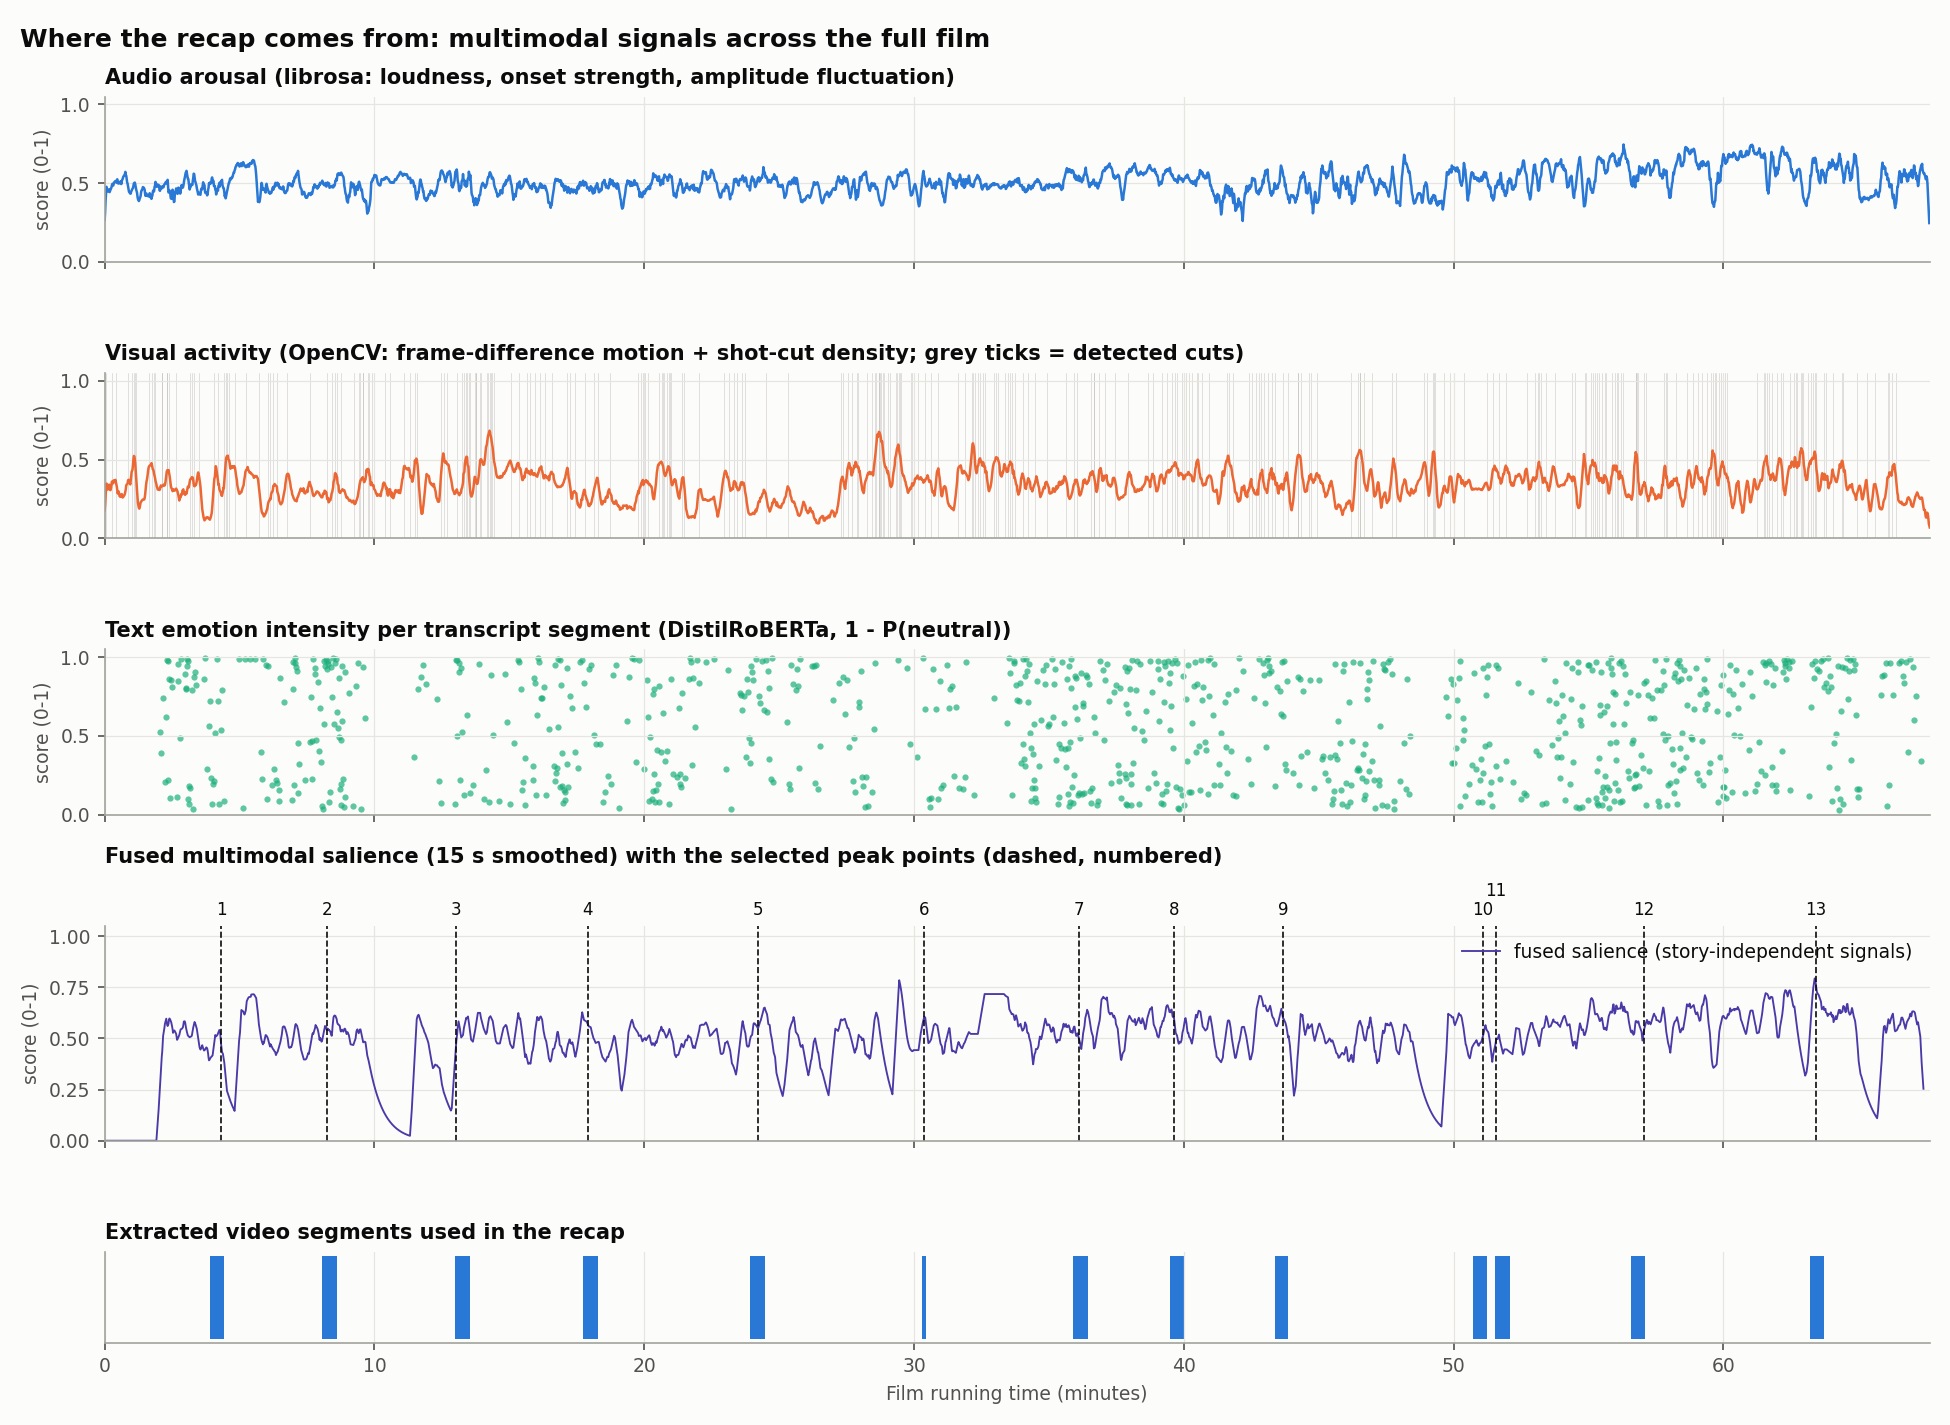

In [9]:
display(Image(filename=str(OUT / "timeline.png"), width=1100))

**Observation.** Peaks spread over the whole running time, from 4 minutes to 63 minutes; the extracted
clips (bottom row) sit on the numbered peaks. Visual activity is highest around the car scenes and the
final apartment scene, and emotion density rises in the second half.

**Interpretation.** Because each story sentence is tied to its own part of the film, the recap covers the
whole story arc rather than clustering where the signals are strongest.

**Key insight.** The intrinsic salience curve alone would favour the noisy second half; anchoring peaks to the
story keeps the recap balanced.

## 8. Video segment extraction (OpenCV) and the movie recap

**Purpose.** Cut the film at the peak timestamps and assemble the recap under ten minutes.

**Methodology.** `recap/segments.py` grows each peak line into a clip using neighbouring dialogue that best
matches the story sentence (up to about 32 s), pads it, snaps both ends to the nearest detected shot cut and
keeps clips chronological and non-overlapping within the time budget. `recap/render.py` then uses **OpenCV**
to seek frame-accurately, read and annotate each clip (original timecode, peak badge, a white border flash at
the exact peak, film-position bar) and to draw chapter cards that narrate each story sentence (offline
text-to-speech, loudness-matched to the film). Audio is assembled sample-locked to the number of written
frames; ffmpeg only muxes and encodes the final MP4.

**Inference.** The thumbnails show the frame at each peak's time index; the edit decision list maps recap time
back to film time.

**Insights.** Snapping cuts to shot boundaries avoids starting a clip on a single stray frame of the
previous shot, which is the most visible artefact of naive timestamp cutting.

**Summary.** The recap's duration is checked against the limit below.

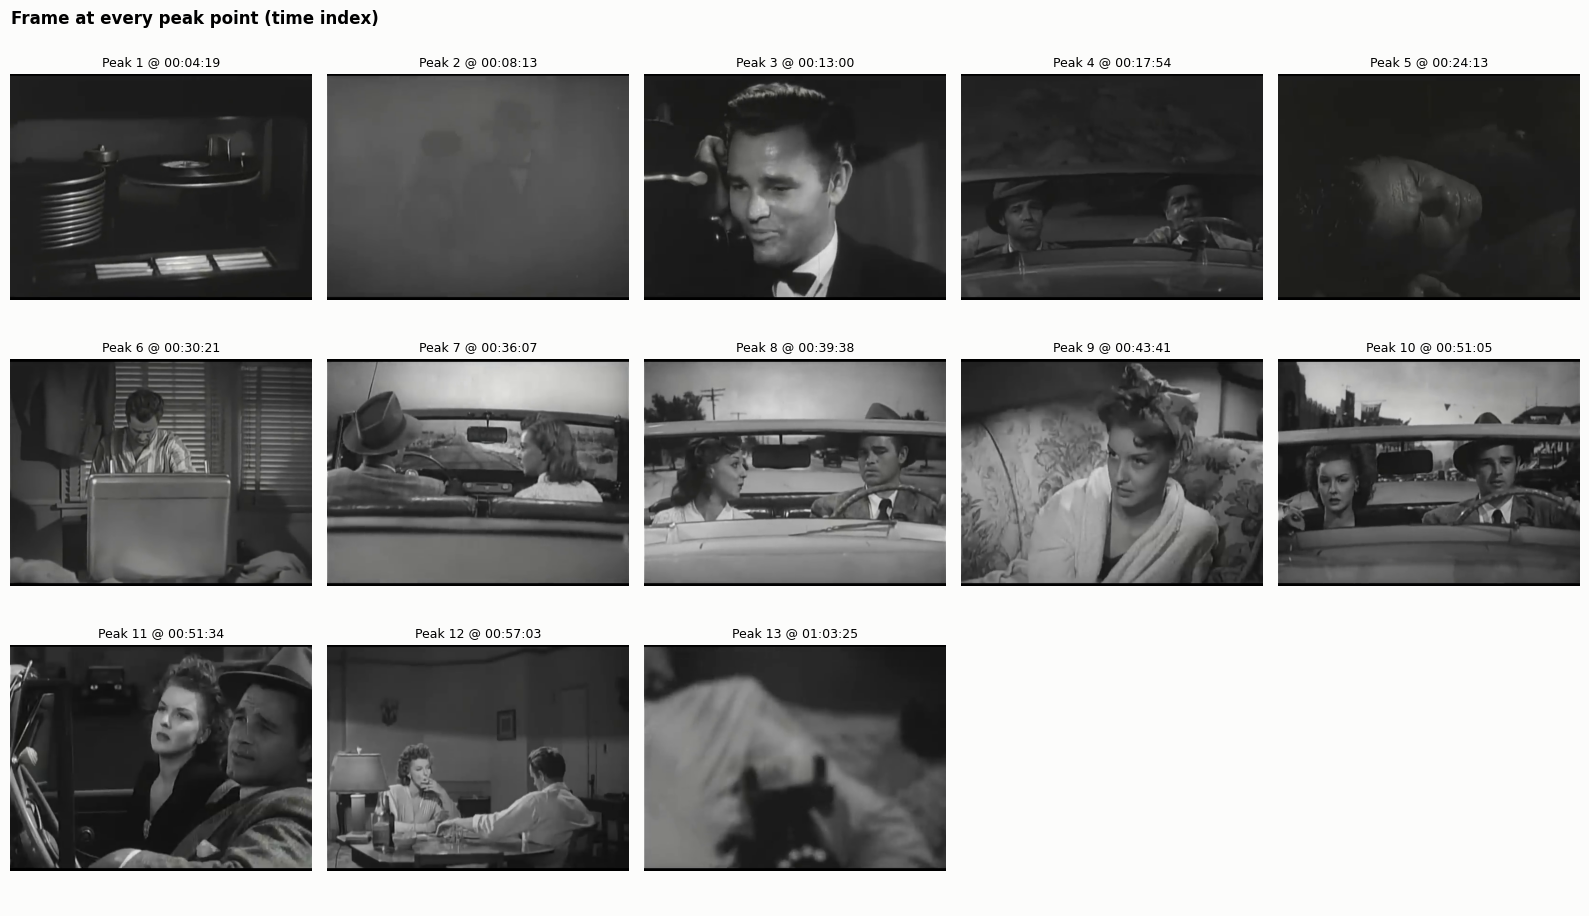

In [10]:
# Peak keyframes, extracted live with OpenCV at each peak's time index
clips = load_json(OUT / "clips.json")
cap = cv2.VideoCapture(VIDEO)
n = len(pk["peaks"])
cols = 5
fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(16, 3.1 * np.ceil(n / cols)))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, pk["peaks"]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(p["timestamp"] * info["fps"]))
    ok, frame = cap.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Peak {p['index']} @ {p['timestamp_hms']}", fontsize=9)
cap.release()
fig.suptitle("Frame at every peak point (time index)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [11]:
# Edit decision list and the hard duration check required by the assignment
edl = pd.read_csv(OUT / "recap_edl.csv")
rinfo = load_json(OUT / "render_info.json")
recap_seconds = rinfo["duration_seconds"]
assert recap_seconds < 600, "recap must be shorter than 10 minutes"
print(f"Recap: {fmt_ts(recap_seconds)} ({recap_seconds:.1f} s) -> under 10 minutes: {recap_seconds < 600}")
print(f"Footage {edl[edl.type == 'clip'].eval('recap_end - recap_start').sum():.0f} s, "
      f"cards {edl[edl.type != 'clip'].eval('recap_end - recap_start').sum():.0f} s, "
      f"compression {info['duration_seconds'] / recap_seconds:.1f}x")
edl.assign(text=edl.text.str.slice(0, 70))

Recap: 00:08:51 (532.0 s) -> under 10 minutes: True
Footage 393 s, cards 139 s, compression 7.6x


,type,peak,recap_start,recap_end,source_start,source_end,text
0,intro,NaN,0.00,5.51,NaN,NaN,An AI-generated recap of Detour (1945).
1,chapter,1.0,5.51,14.65,NaN,NaN,"Al plays a song that reminds him of his girlfriend, Sue, causing him d"
2,clip,1.0,14.65,47.15,233.53,266.03,"You can't, you know. No matter how hard you try. You can change the sc"
3,chapter,2.0,47.15,56.36,NaN,NaN,"Al's girlfriend Sue decides to leave for Hollywood, causing a heated a"
4,clip,2.0,56.36,89.32,483.06,516.02,"Yes, that's right. In the Bush League. I don't get you. We've been str"
5,chapter,3.0,89.32,101.57,NaN,NaN,"Al calls Sue, learns she's working as a hashlinger in Hollywood, and d"
6,clip,3.0,101.57,135.13,778.23,811.81,"This is Al. Oh, baby, it's great to hear from you, too. What's that? Y"
7,chapter,4.0,135.13,146.98,NaN,NaN,"Al picks up Vera, a hitchhiker, and debates whether to keep her or dro"
8,clip,4.0,146.98,179.21,1064.36,1096.60,Tarzan's mate looks like you lost the Bob certainly wasn't a draw. You
9,chapter,5.0,179.21,188.92,NaN,NaN,Al realizes he must hide Charles Haskell's body and take his car to av


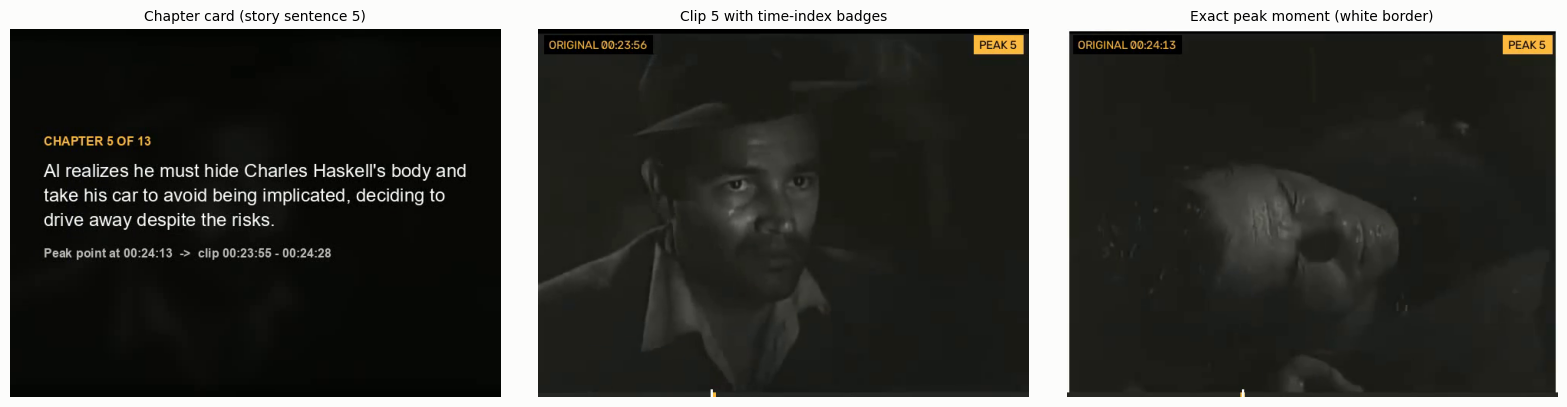

In [12]:
# Three frames from the finished recap: a chapter card, a clip and the clip at its peak moment
cap = cv2.VideoCapture(str(OUT / "movie_recap.mp4"))
fps_r = cap.get(cv2.CAP_PROP_FPS)
row_card, row_clip = edl[edl.type == "chapter"].iloc[4], edl[edl.type == "clip"].iloc[4]
peak5 = pk["peaks"][4]
at_peak = row_clip.recap_start + (peak5["timestamp"] - row_clip.source_start)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, t, title in zip(axes, [row_card.recap_start + 3, row_clip.recap_start + 1, at_peak + 0.1],
                        ["Chapter card (story sentence 5)", "Clip 5 with time-index badges", "Exact peak moment (white border)"]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(t * fps_r))
    ok, frame = cap.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
cap.release()
plt.tight_layout()
plt.show()

**Observation.** The recap runs 8 min 51 s, of which about 6.5 minutes are original footage and the rest
are narrated chapter cards; it compresses the film about 7.6 times.

**Interpretation.** The chapter card states what happens, and the clip that follows shows it with the original
timecode on screen, so the link between summary, peak point, time index and segment is visible to the viewer.

**Key insight.** The duration constraint is enforced in code (planning budget plus an assertion after
rendering), not just hoped for.

## 9. Evaluation

**Purpose.** Measure how good the summary is and whether the recap really contains the intended content.

**Methodology.**
* **BLEU** (Papineni et al., 2002): clipped n-gram precision for n = 1..4, geometric mean, brevity penalty;
  implemented from first principles in `recap/bleu.py` and cross-checked against NLTK and sacreBLEU.
  ROUGE-1/2/L and embedding similarity are reported alongside.
* **Reference:** the human-written Wikipedia plot (526 words). Four baselines of equal length are compared:
  extractive TextRank, the first N words, uniformly spaced lines and random lines.
* **Recap fidelity:** each clip is cut out of the *finished recap* and transcribed again; its BLEU against the
  original transcript at the mapped timestamps checks the whole chain end to end. The session suggested
  about 0.7 as a "good enough" BLEU threshold.
* **Ablation:** peaks selected by text-only weights are compared with the multimodal fusion.

**Inference / Insights / Summary** follow each output below.

In [13]:
# BLEU worked example: own implementation vs NLTK vs sacreBLEU on one sentence pair
from recap.bleu import bleu, tokenize
from nltk.translate.bleu_score import SmoothingFunction, corpus_bleu

cand = "Al picks up Vera, a hitchhiker, who threatens to turn him over to the police."
ref = "Al crosses into California and picks up a hitchhiker named Vera. She blackmails Al by threatening to turn him over to the police."
own = bleu(cand, [ref])
print("n-gram precisions:", [round(p, 3) for p in own["precisions"]], "| brevity penalty:", round(own["bp"], 3))
print(f"BLEU own = {own['bleu']:.4f} | NLTK = "
      f"{corpus_bleu([[tokenize(ref)]], [tokenize(cand)], smoothing_function=SmoothingFunction().method2):.4f} | "
      f"sacreBLEU = {sacrebleu.sentence_bleu(cand, [ref]).score / 100:.4f}")

n-gram precisions: [0.778, 0.556, 0.412, 0.375] | brevity penalty: 0.678
BLEU own = 0.3445 | NLTK = 0.3445 | sacreBLEU = 0.3228


The own implementation matches NLTK exactly (same tokens, same smoothing); sacreBLEU differs slightly
because it uses its own tokenizer and smoothing, which is why papers state which BLEU variant they report.

,bleu4,bleu4_nltk,sacrebleu,bleu1,rouge1,rouge2,rougeL,semantic_similarity,plot_coverage@0.5,words
Summary story (ours),0.0297,0.0297,0.0259,0.2894,0.3942,0.0655,0.1814,0.856,0.56,315
Extractive TextRank,0.0154,0.0154,0.0113,0.234,0.2854,0.0461,0.1258,0.4593,0.16,322
Lead-N (first words),0.0126,0.0126,0.0074,0.2161,0.2047,0.0099,0.0962,0.2897,0.0,315
Uniform segments,0.0145,0.0145,0.0098,0.1973,0.2619,0.0368,0.1248,0.4591,0.08,315
Random segments,0.0104,0.0104,0.0059,0.221,0.2665,0.0221,0.1149,0.4157,0.12,315


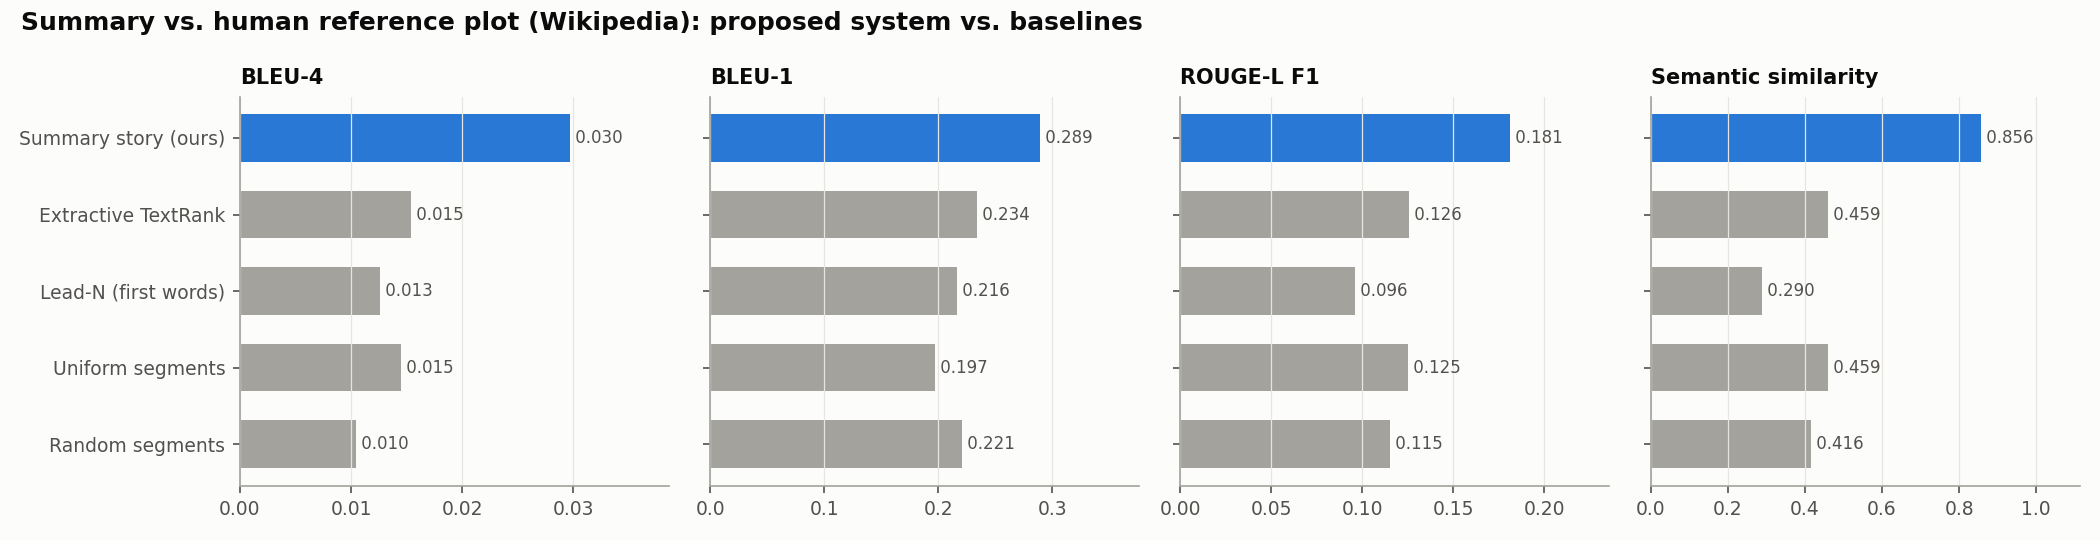

In [14]:
# Summary vs. the human reference, for the proposed story and four baselines
ev = load_json(OUT / "evaluation.json")
cols = ["bleu4", "bleu4_nltk", "sacrebleu", "bleu1", "rouge1", "rouge2", "rougeL", "semantic_similarity", "plot_coverage@0.5", "words"]
display(pd.DataFrame(ev["summary_vs_reference"]).T[cols])
display(Image(filename=str(OUT / "metrics.png"), width=1100))

**Observation.** The summary story scores highest on every metric: BLEU-4 0.030 against at most 0.015 for
the baselines, ROUGE-L 0.18 against at most 0.13, and semantic similarity 0.86 against at most 0.46.

**Interpretation.** Absolute BLEU is low for every system. That is expected: BLEU counts exact word sequences,
and two people summarising the same film rarely use the same four-word phrases. The story is also shorter than
the reference (315 vs 526 words), which costs it a brevity penalty of 0.50. The *ranking* against baselines and
the semantic similarity are the meaningful signals.

**Key insight.** BLEU alone would undervalue a correct abstractive summary; pairing it with semantic
similarity and baselines gives a fair picture.

,mean_clip_bleu,median_clip_bleu,peak_hit_rate@0.6,overall_bleu,mean_narration_bleu
0,0.7954,0.8709,1.0,0.8317,0.9854


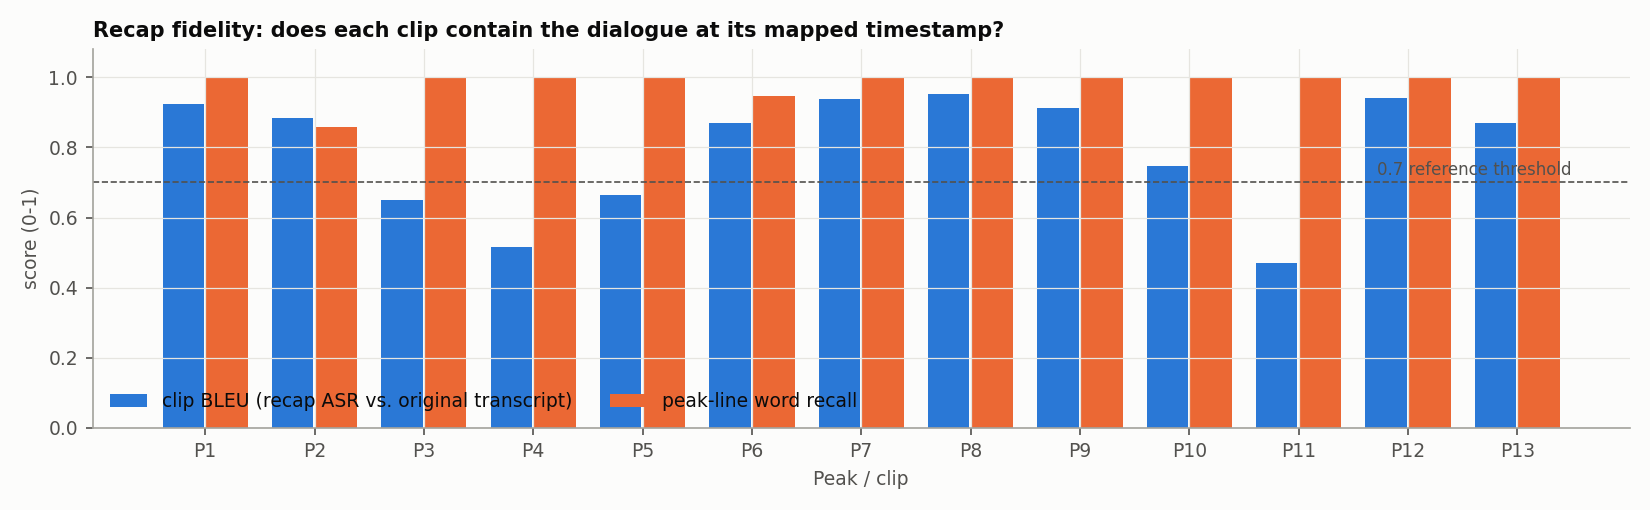

In [15]:
# Recap fidelity: does each recap clip contain the dialogue at its mapped timestamp?
fid = ev["recap_fidelity"]
display(pd.DataFrame([{k: fid[k] for k in ("mean_clip_bleu", "median_clip_bleu", "peak_hit_rate@0.6", "overall_bleu", "mean_narration_bleu")}]))
display(Image(filename=str(OUT / "fidelity.png"), width=950))

**Observation.** Mean clip BLEU is about 0.80 (median 0.87) and every peak line is heard in its clip
(hit rate 1.0); the narration is recognised almost perfectly (BLEU ≈ 0.99).

**Interpretation.** These scores are above the 0.7 threshold discussed in class, which confirms that the
timestamps were mapped correctly and that OpenCV extracted the right segments with synchronised audio. The two
lowest clips (peaks 4 and 11) contain exactly the right dialogue; their scores drop only because the two
Whisper passes format things differently ("1600" vs "$1,600", "1850" vs "eighteen fifty") and the full-film
pass, which uses voice-activity filtering, skipped short interjections such as "Yeah."

**Key insight.** Re-transcribing the output is a cheap end-to-end test of the entire time-index chain.

In [16]:
# Ablation: text-only peak selection vs. multimodal post-fusion
ab = ev["ablation"]
display(pd.DataFrame({"text only (semantic + centrality)": ab["text_only_profile"],
                      "multimodal fusion (proposed)": ab["multimodal_profile"]}).T)
print(f"Peaks moved by adding audio, visual and emotion signals: {ab['peaks_changed']} of {len(pk['peaks'])} "
      f"(mean shift {ab['mean_shift_seconds']} s)")

,semantic,centrality,text_emotion,audio,visual
text only (semantic + centrality),0.8418,0.6771,0.5621,0.5124,0.4425
multimodal fusion (proposed),0.8029,0.6658,0.7790,0.5286,0.4600


Peaks moved by adding audio, visual and emotion signals: 5 of 13 (mean shift 3.41 s)


**Observation.** Fusion moves 5 of 13 peaks by a few seconds. The chosen lines become far more emotional
(0.56 → 0.78) and slightly louder and more visually active, at a small cost in semantic similarity (0.84 → 0.80).

**Interpretation.** Within a scene, the multimodal score prefers the dramatic line (an argument, a threat)
over a neutral line with similar wording, which is what a human editor would pick for a recap.

**Key insight.** The modalities complement each other: text decides *which scene*, audio, video and emotion
decide *which moment* inside it.

## 10. Model comparison (summarisation stage)

**Purpose.** Justify the choice of summariser, the stage with the largest influence on recap quality.

**Methodology.** All variants run on the same transcript and are scored against the same reference. No model
is trained (all are pre-trained, zero-shot), so "training time" is not applicable; "testing time" is the
measured CPU time to summarise the whole film. TextRank is timed live below; the LLM times come from the
pipeline logs.

**Inference.** See the table.

**Insights.** The 7B model is twice as slow as the 3B model but is the only variant whose story a reader can
follow from start to end.

**Summary.** The recommended model is identified below the table.

In [17]:
# Time the extractive baseline live; LLM figures come from the logged pipeline runs
from recap.summarize import textrank_scores, extractive_summary

t0 = time.time()
cent = textrank_scores(segs, model)
_ = extractive_summary(segs, cent, target_words=315)
textrank_seconds = time.time() - t0

ev3 = load_json(OUT.parent / "experiments" / "evaluation_qwen2.5-3b_grounded.json")["summary_vs_reference"]["Summary story (ours)"]
ours, base = ev["summary_vs_reference"], ev["summary_vs_reference"]
rows = [
    ["Qwen2.5-7B, rolling context (proposed)", ours["Summary story (ours)"], "none (pre-trained)", "30.6 min",
     "Coherent full plot arc; best semantic similarity and recap fidelity", "Slowest; still 2 role errors in 13 sentences", "Offline recap generation on a laptop"],
    ["Qwen2.5-3B, rolling context", ev3, "none (pre-trained)", "~14.5 min",
     "2x faster; higher BLEU-1 because it writes more words", "Repeats context sentences; invents events", "Draft summaries, low-RAM machines"],
    ["Extractive TextRank", base["Extractive TextRank"], "none", f"{textrank_seconds:.0f} s",
     "No hallucination; legally safest (original lines only)", "Dialogue lines do not tell a story", "Fallback when no LLM is available"],
    ["Uniform segments", base["Uniform segments"], "none", "< 1 s", "Trivial, unbiased coverage", "Ignores content", "Baseline only"],
    ["Random segments", base["Random segments"], "none", "< 1 s", "Trivial", "Ignores content and order", "Baseline only"],
]
pd.DataFrame([{"Model": r[0], "Performance (BLEU-4 / ROUGE-L / semantic)": f"{r[1]['bleu4']:.3f} / {r[1]['rougeL']:.3f} / {r[1]['semantic_similarity']:.3f}",
               "Training time": r[2], "Testing time": r[3], "Strengths": r[4], "Limitations": r[5], "Suitable use cases": r[6]} for r in rows])

,Model,Performance (BLEU-4 / ROUGE-L / semantic),Training time,Testing time,Strengths,Limitations,Suitable use cases
0,"Qwen2.5-7B, rolling context (proposed)",0.030 / 0.181 / 0.856,none (pre-trained),30.6 min,Coherent full plot arc; best semantic similarity and recap fidelity,Slowest; still 2 role errors in 13 sentences,Offline recap generation on a laptop
1,"Qwen2.5-3B, rolling context",0.040 / 0.191 / 0.812,none (pre-trained),~14.5 min,2x faster; higher BLEU-1 because it writes more words,Repeats context sentences; invents events,"Draft summaries, low-RAM machines"
2,Extractive TextRank,0.015 / 0.126 / 0.459,none,7 s,No hallucination; legally safest (original lines only),Dialogue lines do not tell a story,Fallback when no LLM is available
3,Uniform segments,0.015 / 0.125 / 0.459,none,< 1 s,"Trivial, unbiased coverage",Ignores content,Baseline only
4,Random segments,0.010 / 0.115 / 0.416,none,< 1 s,Trivial,Ignores content and order,Baseline only


**Recommended model: Qwen2.5-7B with rolling context.** It has the highest semantic similarity to the human
plot (0.86) and the best recap fidelity, and it produced the only story that follows the film from the
opening to the ending. The 3B model scores a higher BLEU-4 in some runs only because it writes longer text
(less brevity penalty) while repeating itself; for a recap, coherence and factual order matter more than raw
n-gram overlap. TextRank remains the automatic fallback because it needs no LLM and cannot hallucinate.

## 11. Conclusion

**Overall findings.** The pipeline turns a 67-minute YouTube film into an **8 min 51 s** recap, which is
7.6 times shorter and under the 10-minute limit. It runs fully on a CPU with open models. The summary story
outperforms all four baselines on BLEU, ROUGE and semantic similarity, and the recap passes an end-to-end
fidelity check (clip BLEU about 0.80, every peak line present).

**Best-performing configuration.** Whisper small.en + Qwen2.5-7B rolling-context summary + DP story alignment
+ five-signal post-fusion for peaks + OpenCV rendering with shot-snapped cuts.

**Why it works.** Each stage carries the time index forward explicitly (chunk span → aligned window → peak line
→ clip → recap position), so every claim in the summary can be traced to a moment in the film.

**Practical applications.** Film and series recaps, lecture "previously on" segments (the educational variant
discussed in class), meeting and interview highlight reels, and archive browsing for public-domain collections.

**Limitations.**
* A 7B LLM on a CPU still makes role errors when the transcript has no speaker labels.
* Visual features are low-level (motion, cuts), so silent but important scenes depend on nearby dialogue.
* BLEU against an independently written plot is inherently low for abstractive summaries.

**Future improvements.** Speaker diarisation (e.g. pyannote) to label who speaks; a vision-language model
(CLIP) to match story sentences to frames directly; a larger or fine-tuned LLM; neural TTS for narration;
exposing the stages through a FastAPI service as recommended in the Day 4 session.

## 12. References

1. A. Radford et al., "Robust Speech Recognition via Large-Scale Weak Supervision" (Whisper), 2022; SYSTRAN faster-whisper / CTranslate2.
2. K. Papineni et al., "BLEU: a Method for Automatic Evaluation of Machine Translation", ACL 2002.
3. C.-Y. Lin, "ROUGE: A Package for Automatic Evaluation of Summaries", 2004; C.-Y. Lin and F. J. Och, "ORANGE", COLING 2004 (BLEU smoothing).
4. R. Mihalcea and P. Tarau, "TextRank: Bringing Order into Texts", EMNLP 2004.
5. N. Reimers and I. Gurevych, "Sentence-BERT", EMNLP 2019 (`all-MiniLM-L6-v2`).
6. J. Hartmann, "Emotion English DistilRoBERTa-base", Hugging Face, 2022.
7. Qwen Team, "Qwen2.5 Technical Report", 2024; Ollama.
8. B. McFee et al., "librosa: Audio and Music Signal Analysis in Python", SciPy 2015; OpenCV; yt-dlp; NLTK; M. Post, "A Call for Clarity in Reporting BLEU Scores" (sacreBLEU), 2018.
9. Wikipedia, "Detour (1945 film)", Plot section (CC BY-SA 4.0), used as the reference summary.
10. *Detour* (1945), Producers Releasing Corporation, public domain; YouTube upload https://www.youtube.com/watch?v=tap67KjjPu8.
11. AI11 Module 8 Day 4 class notes, Dr. J. B. Simha (multimodal fusion, BLEU threshold, movie summarisation assignment).